# AIDA 2154 Project Exercise 03 – Visual Feature Inspection

**Question:** Which visual features and course-taught filtering steps might distinguish the five kit icons, and where do they fail?

This notebook uses training cards only. Validation cards remain available for later tuning, and test cards stay held back for final evaluation.

Features are measured within the generator-provided rendering boxes. This gives each icon a known location and does not demonstrate that a method can find or identify icons on a full card. Results are exploratory.

In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

EX01_DIR = Path("../01-synthetic-image-specification")
IMAGE_DIR = EX01_DIR / "images"
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

ICONS = ["access_badge", "safety_vest", "hard_hat", "laptop", "phone"]
CONTRASTS = ["high", "medium", "low"]
SIZES = ["small", "medium", "large"]

manifest = pd.read_csv(EX01_DIR / "manifest.csv")
instances = pd.read_csv(EX01_DIR / "icon_instances.csv")
file_of = manifest.set_index("card_id")["file_name"]

# Training icons only: validation is kept for later tuning and test stays held back
train_icons = instances[instances["split"] == "train"].reset_index(drop=True)

print(f"Training icons: {len(train_icons):,} on {train_icons['card_id'].nunique()} cards")
print("Per icon:", train_icons["icon"].value_counts().reindex(ICONS).to_dict())
print("OpenCV", cv2.__version__)

Training icons: 599 on 273 cards
Per icon: {'access_badge': 151, 'safety_vest': 142, 'hard_hat': 142, 'laptop': 77, 'phone': 87}
OpenCV 4.14.0


## A. Shared definitions from Exercise 02

These definitions are copied from Exercise 02 so this notebook runs on its own. Both difference measures use a 0–255 scale, but they are not equivalent units:

- **Colour difference:** Euclidean RGB distance from the background (236, 236, 230), scaled so the largest possible distance (background to black) equals 255.
- **Grayscale difference:** the absolute difference between a pixel's grayscale value and the background's grayscale value.

The consistency check confirms that the copied grayscale and colour-difference calculations reproduce Exercise 02's saved icon-signal summary. Exercise 02 reported colour difference as raw RGB distance, so values are converted back before comparison. The check requires `icon_contrast.csv` from a completed Exercise 02 run.

In [2]:
BACKGROUND_RGB = (236, 236, 230)
BACKGROUND_GRAY = int(cv2.cvtColor(np.uint8([[BACKGROUND_RGB]]), cv2.COLOR_RGB2GRAY)[0, 0])
MAX_COLOUR_DIFF = float(np.linalg.norm(BACKGROUND_RGB))  # background to black

def load_rgb(file_name):
    """Read a card with OpenCV and convert BGR to RGB."""
    return cv2.cvtColor(cv2.imread(str(IMAGE_DIR / file_name)), cv2.COLOR_BGR2RGB)

def difference_maps(rgb):
    """Colour and grayscale difference from the background, both on a 0-255 scale (not equivalent units)."""
    colour_diff = np.linalg.norm(rgb.astype(float) - BACKGROUND_RGB, axis=2) / MAX_COLOUR_DIFF * 255
    gray_diff = np.abs(cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY).astype(float) - BACKGROUND_GRAY)
    return colour_diff.astype(np.float32), gray_diff.astype(np.float32)

def icon_crop(icon_row):
    """The icon's rendering box from its card, in RGB."""
    return load_rgb(file_of[icon_row.card_id])[icon_row.y0:icon_row.y1, icon_row.x0:icon_row.x1]

# Consistency check: the copied calculations reproduce Exercise 02's saved icon-signal summary.
# Exercise 02 reported colour difference in raw RGB distance, so the 0-255 values are converted back first.
ex02 = pd.read_csv(EX01_DIR.parent / "02-image-quality-and-preprocessing" / "outputs" / "icon_contrast.csv")
gray_means, colour_means = [], []
for row in train_icons.itertuples():
    colour_diff, gray_diff = difference_maps(icon_crop(row))
    icon_pixels = colour_diff > 0
    gray_means.append(gray_diff[icon_pixels].mean())
    colour_means.append(colour_diff[icon_pixels].mean() * MAX_COLOUR_DIFF / 255)
recomputed = (train_icons.assign(gray_diff=gray_means, colour_diff=colour_means)
              .groupby(["icon", "contrast_level"])[["gray_diff", "colour_diff"]].median().round(1))
compare = ex02.set_index(["icon", "contrast_level"])[["gray_diff", "colour_diff"]].join(recomputed, rsuffix="_now")
for measure in ["gray_diff", "colour_diff"]:
    matches = np.allclose(compare[measure], compare[f"{measure}_now"], atol=0.05, rtol=0)
    assert matches, f"{measure} results differ from Exercise 02."
    print(f"{measure} summary matches Exercise 02:", matches)
print("Background gray level:", BACKGROUND_GRAY)

gray_diff summary matches Exercise 02: True
colour_diff summary matches Exercise 02: True
Background gray level: 235


## B. Foreground mask threshold sweep

A foreground mask keeps pixels whose difference from the background is above a threshold. This section compares thresholds of 2, 5, 10, 20, and 40 on the colour-difference and grayscale-difference maps. The two maps both use a 0–255 scale but are not equivalent units, so the same threshold number does not mean the same amount of difference.

**Reference foreground:** inside each icon's known rendering box, the pixels that differ from the background in colour at all. **Retention** is the share of reference pixels a mask keeps. Because the reference is defined by colour, a pixel that matches the background's grayscale value can never be kept by a grayscale mask; this is the effect being measured.

Masks are limited to reference pixels, so this experiment measures retention only and does not evaluate false foreground pixels. Exercise 02, Part B showed that the content area outside icon boxes is exactly the background colour, so within the cropped content area no background pixel would pass any of these thresholds. The header and border would pass, which is one reason later methods use the content crop. Retention measures how much of a known icon survives a threshold, not detection accuracy.

**Working threshold:** A colour-difference threshold of 10 is used for the remaining experiments. In this training sample, it produces a non-empty mask for every icon and retains a median of at least 70% of reference pixels for each low-contrast icon type. This is a provisional setting for inspecting features, not an optimized detection threshold or evidence of robustness to noise.

The badge's pale internal details may be removed by thresholding. The example masks show where pixels disappear, while retention summarizes the total loss.

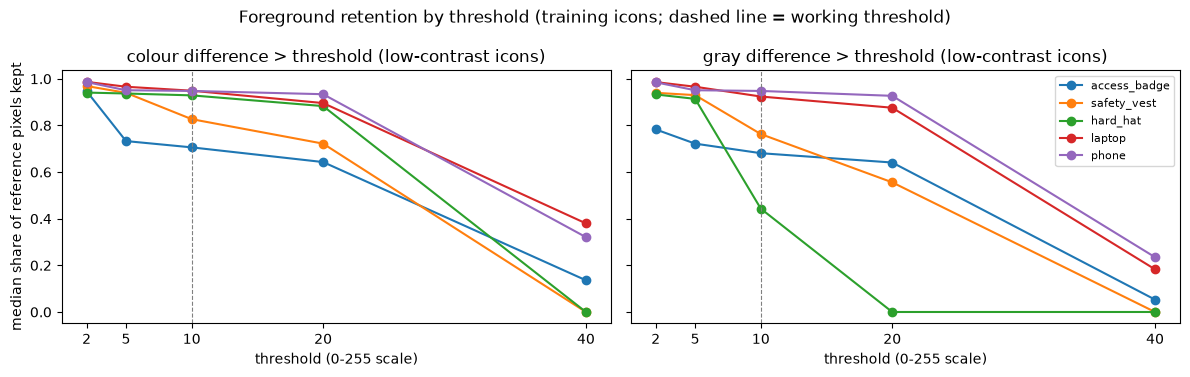

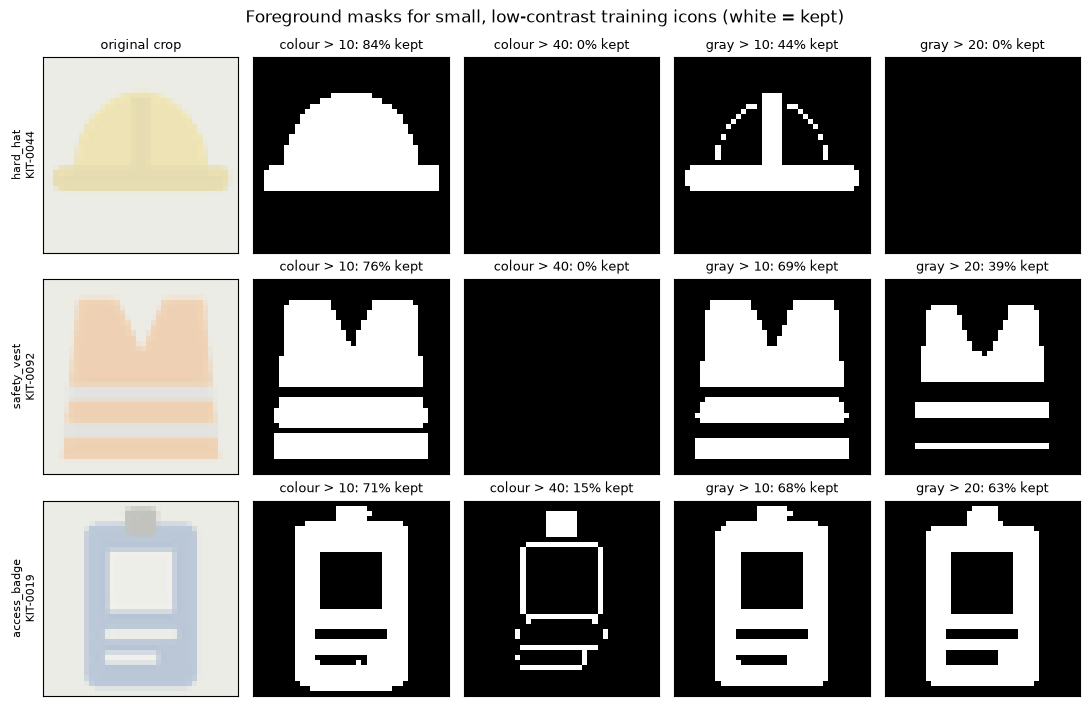

Masks with no pixels kept (all training icons):


threshold,2,5,10,20,40
representation,,,,,
colour,0,0,0,0,81
gray,0,0,0,38,133


icon                      access_badge  safety_vest  hard_hat  laptop  phone
representation threshold                                                    
colour         2                 0.947        0.969     0.941   0.987  0.986
               5                 0.733        0.940     0.937   0.966  0.951
               10                0.706        0.827     0.929   0.949  0.948
               20                0.643        0.722     0.883   0.896  0.934
               40                0.136        0.000     0.000   0.380  0.321
gray           2                 0.783        0.940     0.933   0.986  0.985
               5                 0.722        0.930     0.914   0.966  0.951
               10                0.681        0.763     0.443   0.924  0.948
               20                0.641        0.556     0.000   0.876  0.927
               40                0.053        0.000     0.000   0.183  0.235

In [3]:
THRESHOLDS = [2, 5, 10, 20, 40]   # on the 0-255 difference scales (colour and grayscale are not equivalent units)
WORKING_THRESHOLD = 10            # colour-difference threshold carried into Parts C-E; see the Markdown above

# Each training icon's difference maps and reference foreground, reused in later parts
crops = {}
sweep_rows = []
for row in train_icons.itertuples():
    rgb = icon_crop(row)
    colour_diff, gray_diff = difference_maps(rgb)
    reference = colour_diff > 0   # reference foreground: pixels in the box that differ from the background
    if not reference.any():
        raise ValueError(f"No reference foreground for {row.card_id}, {row.icon}")
    crops[row.Index] = {"rgb": rgb, "colour_diff": colour_diff, "gray_diff": gray_diff, "reference": reference}
    for representation, diff in [("colour", colour_diff), ("gray", gray_diff)]:
        for t in THRESHOLDS:
            kept = (diff > t) & reference
            sweep_rows.append({"icon": row.icon, "contrast_level": row.contrast_level,
                               "representation": representation, "threshold": t,
                               "retention": kept.sum() / reference.sum(), "empty": not kept.any()})
sweep = pd.DataFrame(sweep_rows)

mask_threshold_sweep = (sweep.groupby(["representation", "threshold", "icon", "contrast_level"])
                        .agg(icons=("retention", "size"), median_retention=("retention", "median"),
                             min_retention=("retention", "min"), empty_masks=("empty", "sum"))
                        .round(3).reset_index())
mask_threshold_sweep.to_csv(OUTPUT_DIR / "mask_threshold_sweep.csv", index=False)

# Chart: median retention for low-contrast icons as the threshold rises
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, representation in zip(axes, ["colour", "gray"]):
    low = mask_threshold_sweep.query("representation == @representation and contrast_level == 'low'")
    for icon in ICONS:
        line = low[low["icon"] == icon]
        ax.plot(line["threshold"], line["median_retention"], marker="o", label=icon)
    ax.axvline(WORKING_THRESHOLD, color="grey", ls="--", lw=0.8)
    ax.set_title(f"{representation} difference > threshold (low-contrast icons)")
    ax.set_xlabel("threshold (0-255 scale)")
    ax.set_xticks(THRESHOLDS)
axes[0].set_ylabel("median share of reference pixels kept")
axes[1].legend(fontsize=8)
fig.suptitle("Foreground retention by threshold (training icons; dashed line = working threshold)")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "mask_retention.png", dpi=120)
plt.show()

# Example masks: the first small, low-contrast training example of three icons
examples = [train_icons.query("icon == @icon and contrast_level == 'low' and scale_level == 'small'").index[0]
            for icon in ["hard_hat", "safety_vest", "access_badge"]]
panels = [("colour", 10), ("colour", 40), ("gray", 10), ("gray", 20)]
fig, axes = plt.subplots(len(examples), len(panels) + 1, figsize=(11, 2.4 * len(examples)), squeeze=False)
for r, idx in enumerate(examples):
    crop = crops[idx]
    axes[r, 0].imshow(crop["rgb"], interpolation="nearest")
    axes[r, 0].set_ylabel(f"{train_icons.at[idx, 'icon']}\n{train_icons.at[idx, 'card_id']}", fontsize=8)
    axes[r, 0].set_title("original crop" if r == 0 else "", fontsize=9)
    for c, (representation, t) in enumerate(panels, start=1):
        mask = (crop[f"{representation}_diff"] > t) & crop["reference"]
        axes[r, c].imshow(mask, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
        axes[r, c].set_title(f"{representation} > {t}: {mask.sum() / crop['reference'].sum():.0%} kept", fontsize=9)
for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle("Foreground masks for small, low-contrast training icons (white = kept)")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "mask_examples.png", dpi=120)
plt.show()

print("Masks with no pixels kept (all training icons):")
display(mask_threshold_sweep.pivot_table(index="representation", columns="threshold",
                                         values="empty_masks", aggfunc="sum"))
mask_threshold_sweep.query("contrast_level == 'low'").pivot_table(
    index=["representation", "threshold"], columns="icon", values="median_retention").reindex(columns=ICONS)

## C. Shape features

Shape features are measured on the foreground mask (colour difference > 10) inside each training icon's rendering box. All foreground pieces are combined, because some low-contrast icons split into separate pieces when pale parts fall below the threshold.

- **Aspect ratio:** width ÷ height of the tightest upright rectangle around all foreground pixels (not the square rendering box).
- **Fill ratio:** foreground pixels ÷ the area of that rectangle.
- **Rasterized solidity:** foreground pixels ÷ the pixels inside a filled convex hull drawn around all foreground pixels. This pixel-count version is consistent with the mask but differs slightly from contour-area solidity used in many OpenCV examples. When an icon has several pieces, one hull is drawn around all of them, so gaps between pieces lower solidity.
- **Pieces:** the number of separate foreground regions (8-connected).

An empty mask would be recorded as missing shape measurements, with zero pieces. For comparison, the aspect ratio of the largest piece alone is also recorded; the right-hand chart shows it only for safety-vest masks that split into more than one piece.

The generator repeats the same drawing for each icon, size, and contrast combination. The distinct training-crop count is reported below, so repeated instances are not treated as independent shape variations. Many chart points overlap, and any separation describes these generated appearances rather than natural variation or full-card detection.

Distinct icon images among 599 training icons: 45
Icons whose mask has more than one piece: {('laptop', 'low'): 12, ('safety_vest', 'low'): 43}


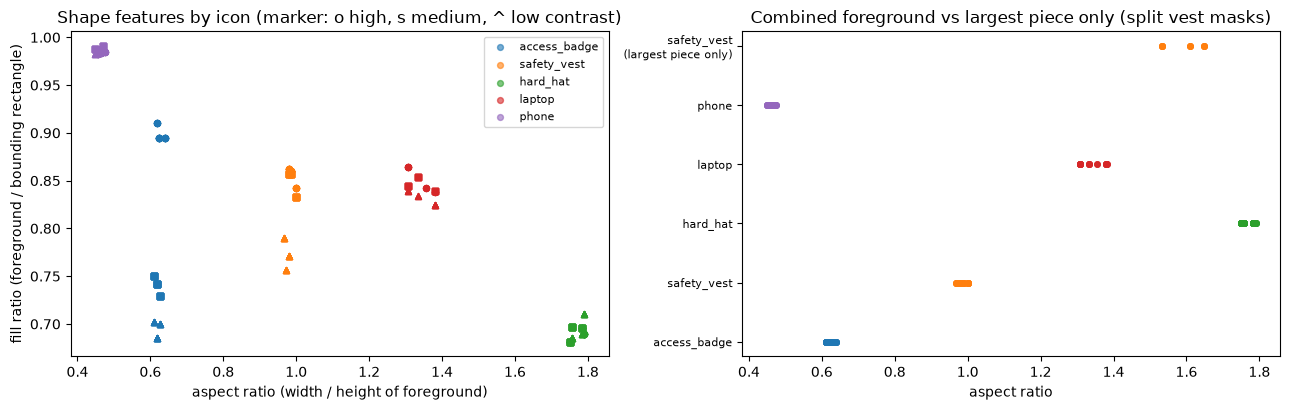

aspect_ratio              fill_ratio              solidity  \
                      min median   max        min median   max      min   
icon                                                                      
access_badge         0.61   0.62  0.64       0.69   0.74  0.91     0.73   
safety_vest          0.97   0.98  1.00       0.76   0.84  0.86     0.82   
hard_hat             1.75   1.78  1.79       0.68   0.69  0.71     0.94   
laptop               1.31   1.33  1.38       0.82   0.84  0.86     0.91   
phone                0.45   0.46  0.48       0.98   0.99  0.99     1.00   

                          pieces             
             median   max    min median max  
icon                                         
access_badge   0.78  0.96      1    1.0   1  
safety_vest    0.92  0.93      1    1.0   5  
hard_hat       0.95  0.95      1    1.0   1  
laptop         0.93  0.94      1    1.0   2  
phone          1.00  1.00      1    1.0   1

In [4]:
def shape_features(mask):
    """Shape measurements over the combined foreground (all pieces together); missing if the mask is empty."""
    if not mask.any():
        return {"aspect_ratio": np.nan, "fill_ratio": np.nan, "solidity": np.nan, "pieces": 0,
                "largest_piece_aspect": np.nan}
    points = cv2.findNonZero(mask.astype(np.uint8))
    _, _, w, h = cv2.boundingRect(points)                     # tightest upright rectangle around all foreground pixels
    hull_mask = np.zeros(mask.shape, dtype=np.uint8)
    cv2.fillConvexPoly(hull_mask, cv2.convexHull(points), 1)  # convex hull drawn as pixels, so units match the mask
    # For comparison: the aspect ratio if only the largest piece were measured
    n, _, stats, _ = cv2.connectedComponentsWithStats(mask.astype(np.uint8), connectivity=8)
    largest = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    largest_aspect = stats[largest, cv2.CC_STAT_WIDTH] / stats[largest, cv2.CC_STAT_HEIGHT]
    return {"aspect_ratio": w / h, "fill_ratio": mask.sum() / (w * h),
            "solidity": mask.sum() / hull_mask.sum(), "pieces": n - 1, "largest_piece_aspect": largest_aspect}

shape_rows = []
for row in train_icons.itertuples():
    mask = crops[row.Index]["colour_diff"] > WORKING_THRESHOLD
    shape_rows.append({"icon": row.icon, "scale_level": row.scale_level, "contrast_level": row.contrast_level,
                       **shape_features(mask)})
shapes = pd.DataFrame(shape_rows, index=train_icons.index)

# Icons of the same type, size, and contrast are drawn identically, so many crops are pixel-for-pixel copies
distinct_crops = len({(crop["rgb"].shape, crop["rgb"].tobytes()) for crop in crops.values()})
print(f"Distinct icon images among {len(crops)} training icons: {distinct_crops}")

shape_summary = (shapes.groupby("icon")[["aspect_ratio", "fill_ratio", "solidity", "pieces"]]
                 .agg(["min", "median", "max"]).round(2).reindex(ICONS))
split = shapes[shapes["pieces"] > 1]
print("Icons whose mask has more than one piece:",
      split.groupby(["icon", "contrast_level"]).size().to_dict())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
markers = {"high": "o", "medium": "s", "low": "^"}
for icon in ICONS:
    for contrast, marker in markers.items():
        group = shapes[(shapes["icon"] == icon) & (shapes["contrast_level"] == contrast)]
        axes[0].scatter(group["aspect_ratio"], group["fill_ratio"], marker=marker, s=18, alpha=0.6,
                        color=f"C{ICONS.index(icon)}", label=icon if contrast == "high" else None)
axes[0].set_xlabel("aspect ratio (width / height of foreground)")
axes[0].set_ylabel("fill ratio (foreground / bounding rectangle)")
axes[0].set_title("Shape features by icon (marker: o high, s medium, ^ low contrast)")
axes[0].legend(fontsize=8)

# Failure case: measuring only the largest piece of a split mask
rows = [(icon, shapes.loc[shapes["icon"] == icon, "aspect_ratio"]) for icon in ICONS]
rows.append(("safety_vest\n(largest piece only)", split.loc[split["icon"] == "safety_vest", "largest_piece_aspect"]))
for y, (label, values) in enumerate(rows):
    colour = "C1" if label.startswith("safety_vest") else f"C{ICONS.index(label)}"
    axes[1].scatter(values, np.full(len(values), y), s=14, alpha=0.5, color=colour)
axes[1].set_yticks(range(len(rows)))
axes[1].set_yticklabels([label for label, _ in rows], fontsize=8)
axes[1].set_xlabel("aspect ratio")
axes[1].set_title("Combined foreground vs largest piece only (split vest masks)")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "shape_features.png", dpi=120)
plt.show()

shape_summary

## D. Colour features

Colour features are measured on the same foreground mask (colour difference > 10), after converting each crop from RGB to HSV with OpenCV. OpenCV stores hue on a 0–179 scale (degrees divided by two) and saturation on a 0–255 scale.

- **Saturation:** the median saturation of the foreground pixels.
- **Pixels meeting the saturation cutoff:** the share of foreground pixels with saturation of at least 20. Hue is unreliable for nearly grey pixels, so it is measured only on these pixels. The cutoff of 20 is a provisional setting.
- **Hue:** the average hue of those pixels. Because hue wraps around (red appears at both ends of the scale), a supporting circular-averaging calculation treats each hue as an angle, averages the angles, and converts the result back to OpenCV's 0–179 scale.
- **Hue consistency:** A value from 0 to 1 indicating how concentrated the selected hues are. Values near zero mean there is no clear average hue direction; values near one mean the hues are closely aligned.

Hue is recorded as missing if no foreground pixel meets the saturation cutoff, or if the hues have no clear average direction. All features from Parts C and D are saved to `outputs/feature_table.csv`, one row per training icon. As in Part C, many icons are identical drawings, so repeated rows are not independent variations.

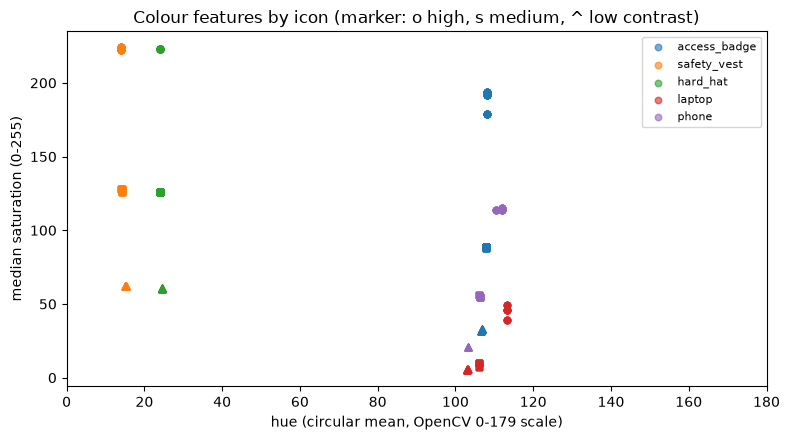

Icons with no hue measured: 0


hue  hue_consistency  saturation  \
icon         contrast_level                                        
access_badge high            108.21             0.99       192.0   
             medium          107.93             1.00        89.0   
             low             106.77             1.00        33.0   
safety_vest  high             14.05             1.00       223.0   
             medium           14.17             1.00       128.0   
             low              15.22             1.00        62.0   
hard_hat     high             24.04             1.00       223.0   
             medium           24.07             1.00       126.0   
             low              24.61             1.00        61.0   
laptop       high            113.18             0.97        46.0   
             medium          106.08             1.00        10.0   
             low             103.08             1.00         6.0   
phone        high            111.98             0.97       114.0   
             medium          106.29             1.00        55.0   
             low             103.14             1.00        21.0   

                             pct_pixels_meeting_saturation_cutoff  
icon         contrast_level                                        
access_badge high                                           73.01  
             medium                                         85.19  
             low                                            85.00  
safety_vest  high                                           83.08  
             medium                                         82.88  
             low                                            92.11  
hard_hat     high                                          100.00  
             medium                                        100.00  
             low                                           100.00  
laptop       high                                           86.88  
             medium                                         49.40  
             low                                            44.55  
phone        high                                           88.90  
             medium                                         63.26  
             low                                            55.33

In [5]:
MIN_SATURATION = 20  # hue is only measured on pixels with at least this saturation (0-255 scale); provisional

def colour_features(rgb, mask):
    """Hue and saturation of foreground pixels; hue uses a circular mean because it wraps around."""
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)       # OpenCV: hue 0-179 (degrees / 2), saturation 0-255
    hue, sat = hsv[..., 0][mask].astype(float), hsv[..., 1][mask].astype(float)
    if sat.size == 0:
        return {"hue": np.nan, "hue_consistency": np.nan, "saturation": np.nan,
                "pct_pixels_meeting_saturation_cutoff": np.nan}
    coloured = sat >= MIN_SATURATION
    result = {"saturation": np.median(sat), "pct_pixels_meeting_saturation_cutoff": coloured.mean() * 100}
    if not coloured.any():
        return {**result, "hue": np.nan, "hue_consistency": np.nan}
    angles = np.deg2rad(hue[coloured] * 2)            # back to 0-360 degrees, then radians
    mean_cos, mean_sin = np.cos(angles).mean(), np.sin(angles).mean()
    consistency = np.hypot(mean_cos, mean_sin)        # 1 = hues closely aligned, near 0 = no clear direction
    mean_hue = (np.rad2deg(np.arctan2(mean_sin, mean_cos)) % 360) / 2 if consistency > 1e-6 else np.nan
    return {**result, "hue": mean_hue, "hue_consistency": consistency}  # hue on OpenCV's 0-179 scale

colour_rows = []
for row in train_icons.itertuples():
    crop = crops[row.Index]
    colour_rows.append(colour_features(crop["rgb"], crop["colour_diff"] > WORKING_THRESHOLD))
colours = pd.DataFrame(colour_rows, index=train_icons.index)

colour_summary = (colours.join(train_icons[["icon", "contrast_level"]])
                  .groupby(["icon", "contrast_level"])[["hue", "hue_consistency", "saturation",
                                                       "pct_pixels_meeting_saturation_cutoff"]]
                  .median().round(2)
                  .reindex(pd.MultiIndex.from_product([ICONS, CONTRASTS], names=["icon", "contrast_level"])))

# One row per training icon with every feature, for later parts and exercises
feature_table = pd.concat([train_icons[["card_id", "icon", "scale_level", "contrast_level", "x0", "y0", "x1", "y1"]],
                           shapes.drop(columns=["icon", "scale_level", "contrast_level"]), colours], axis=1)
feature_table.round(4).to_csv(OUTPUT_DIR / "feature_table.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4.5))
for icon in ICONS:
    for contrast, marker in markers.items():
        group = feature_table[(feature_table["icon"] == icon) & (feature_table["contrast_level"] == contrast)]
        ax.scatter(group["hue"], group["saturation"], marker=marker, s=22, alpha=0.6,
                   color=f"C{ICONS.index(icon)}", label=icon if contrast == "high" else None)
ax.set_xlim(0, 180)
ax.set_xlabel("hue (circular mean, OpenCV 0-179 scale)")
ax.set_ylabel("median saturation (0-255)")
ax.set_title("Colour features by icon (marker: o high, s medium, ^ low contrast)")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "colour_features.png", dpi=120)
plt.show()

print("Icons with no hue measured:", int(feature_table["hue"].isna().sum()))
colour_summary

## E. Canny edge filter

Canny identifies edges from changes in image intensity. It is applied to each training icon’s grayscale crop and colour-difference map, with the latter converted to 8-bit values for OpenCV’s Canny function. This conversion can truncate very small differences.

Both representations use fixed hysteresis thresholds of 50 and 150, with OpenCV's default 3 × 3 Sobel aperture, the L1 gradient measure, and no separate blur. These settings are exploratory and are not tuned. The thresholds act on image gradients, and because the representations produce different gradients, equal thresholds do not provide equivalent sensitivity. Lower thresholds may recover edges missed here.

The summary reports how many icons contain any edge pixels and the median edge-pixel count by icon and contrast level. Having edges does not mean the outline is complete or the icon has been identified. Counts also depend on size and internal details, so they are not treated as a direct measure of quality across icon types.

This experiment compares one filter at one setting within known icon locations; it does not evaluate full-card detection.

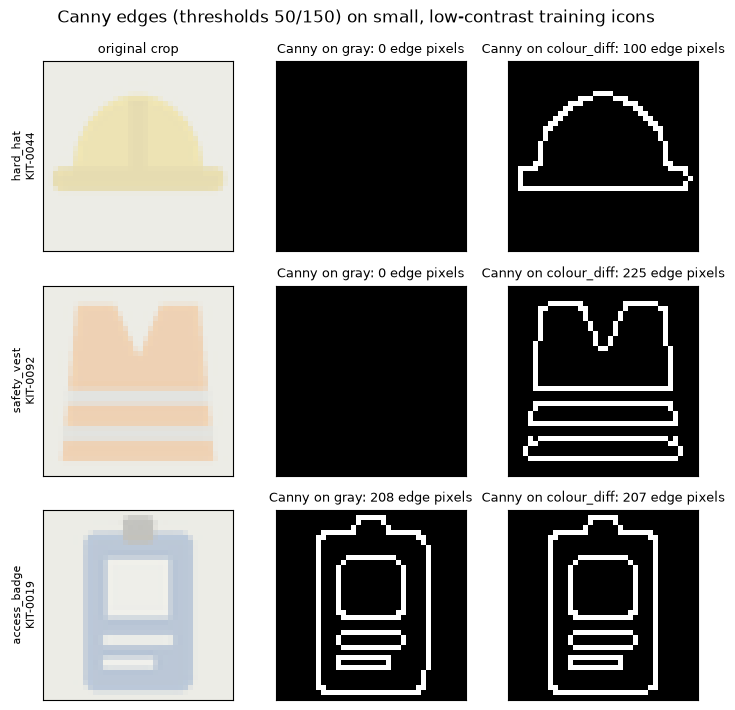

Icons with no edges: {'gray': 81}


icons  icons_with_edges  \
representation icon         contrast_level                            
gray           access_badge high               50                50   
                            medium             55                55   
                            low                46                46   
               safety_vest  high               51                51   
                            medium             48                48   
                            low                43                 0   
               hard_hat     high               52                52   
                            medium             52                52   
                            low                38                 0   
               laptop       high               24                24   
                            medium             27                27   
                            low                26                26   
               phone        high               30                30   
                            medium             35                35   
                            low                22                22   
colour_diff    access_badge high               50                50   
                            medium             55                55   
                            low                46                46   
               safety_vest  high               51                51   
                            medium             48                48   
                            low                43                43   
               hard_hat     high               52                52   
                            medium             52                52   
                            low                38                38   
               laptop       high               24                24   
                            medium             27                27   
                            low                26                26   
               phone        high               30                30   
                            medium             35                35   
                            low                22                22   

                                            median_edge_pixels  
representation icon         contrast_level                      
gray           access_badge high                         352.0  
                            medium                       352.0  
                            low                          352.0  
               safety_vest  high                         403.0  
                            medium                       399.0  
                            low                            0.0  
               hard_hat     high                         247.0  
                            medium                       245.0  
                            low                            0.0  
               laptop       high                         403.0  
                            medium                       403.0  
                            low                          275.0  
               phone        high                         302.0  
                            medium                       302.0  
                            low                          162.0  
colour_diff    access_badge high                         352.0  
                            medium                       352.0  
                            low                          352.0  
               safety_vest  high                         395.0  
                            medium                       391.0  
                            low                          386.0  
               hard_hat     high                         168.0  
                            medium                       168.0  
                            low                          167.0  
               laptop       high                         403.0  
                

In [6]:
CANNY_LOW, CANNY_HIGH = 50, 150   # chosen fixed hysteresis thresholds; exploratory, not tuned
CANNY_APERTURE = 3                # Sobel kernel size (OpenCV default)
CANNY_L2 = False                  # L1 gradient measure (OpenCV default); no separate blur is applied

edge_rows, edge_maps = [], {}
for row in train_icons.itertuples():
    crop = crops[row.Index]
    images = {"gray": cv2.cvtColor(crop["rgb"], cv2.COLOR_RGB2GRAY),
              "colour_diff": np.clip(crop["colour_diff"], 0, 255).astype(np.uint8)}  # Canny needs 8-bit input
    for representation, image in images.items():
        edges = cv2.Canny(image, CANNY_LOW, CANNY_HIGH, apertureSize=CANNY_APERTURE, L2gradient=CANNY_L2)
        edge_maps[(row.Index, representation)] = edges
        edge_rows.append({"icon": row.icon, "contrast_level": row.contrast_level, "representation": representation,
                          "edge_pixels": int((edges > 0).sum())})
edge_results = pd.DataFrame(edge_rows)
edge_results["has_edges"] = edge_results["edge_pixels"] > 0
edge_summary = (edge_results.groupby(["representation", "icon", "contrast_level"])
                .agg(icons=("has_edges", "size"), icons_with_edges=("has_edges", "sum"),
                     median_edge_pixels=("edge_pixels", "median"))
                .reindex(pd.MultiIndex.from_product([["gray", "colour_diff"], ICONS, CONTRASTS],
                                                    names=["representation", "icon", "contrast_level"])))
edge_summary.to_csv(OUTPUT_DIR / "edge_summary.csv")

# Example edges for the same low-contrast icons shown in Part B
fig, axes = plt.subplots(len(examples), 3, figsize=(7.5, 2.4 * len(examples)), squeeze=False)
for r, idx in enumerate(examples):
    axes[r, 0].imshow(crops[idx]["rgb"], interpolation="nearest")
    axes[r, 0].set_ylabel(f"{train_icons.at[idx, 'icon']}\n{train_icons.at[idx, 'card_id']}", fontsize=8)
    axes[r, 0].set_title("original crop" if r == 0 else "", fontsize=9)
    for c, representation in enumerate(["gray", "colour_diff"], start=1):
        edges = edge_maps[(idx, representation)]
        axes[r, c].imshow(edges, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
        axes[r, c].set_title(f"Canny on {representation}: {int((edges > 0).sum())} edge pixels", fontsize=9)
for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle(f"Canny edges (thresholds {CANNY_LOW}/{CANNY_HIGH}) on small, low-contrast training icons")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "edge_examples.png", dpi=120)
plt.show()

print("Icons with no edges:", edge_results.loc[~edge_results["has_edges"]].groupby("representation").size().to_dict())
edge_summary

## F. Parameter notes

The main settings used in this notebook are recorded below with their values and reasons, and saved to `outputs/parameter_notes.csv`. Settings marked provisional or exploratory were chosen for inspecting features on training icons; none was optimized for detection.

In [7]:
parameter_notes = pd.DataFrame([
    ("Data", "Training icons only", f"{len(train_icons)} icons", "Validation kept for later tuning; test held back"),
    ("A", "Colour difference", "Euclidean RGB distance from (236, 236, 230), scaled so background-to-black = 255",
     "Same definition as Exercise 02"),
    ("A", "Grayscale difference", f"|OpenCV grayscale - {BACKGROUND_GRAY}|", "Same definition as Exercise 02"),
    ("B", "Reference foreground", "Colour difference > 0 inside the rendering box", "Defines what retention is measured against"),
    ("B", "Thresholds compared", ", ".join(map(str, THRESHOLDS)), "Exploratory sweep on the 0-255 scales"),
    ("B-E", "Working threshold", f"Colour difference > {WORKING_THRESHOLD}",
     "Provisional; non-empty mask for every training icon; not optimized or tested for noise"),
    ("C", "Pieces", "8-connected components", "Diagonal neighbours count as connected"),
    ("C", "Shape measurements", "Combined foreground; rasterized convex hull", "Split masks would distort largest-piece shape"),
    ("D", "Colour space", "OpenCV HSV: hue 0-179, saturation 0-255", "OpenCV's 8-bit convention"),
    ("D", "Minimum saturation for hue", str(MIN_SATURATION), "Provisional; hue is unreliable for nearly grey pixels"),
    ("D", "Hue average", "Circular mean; missing if consistency <= 1e-6", "Hue wraps around"),
    ("E", "Canny thresholds", f"{CANNY_LOW} / {CANNY_HIGH}", "Chosen fixed values; exploratory, not tuned"),
    ("E", "Canny aperture and gradient", f"{CANNY_APERTURE} x {CANNY_APERTURE} Sobel; L1 gradient",
     "OpenCV defaults, stated explicitly"),
    ("E", "Blur before Canny", "None", "Cards contain no noise"),
    ("E", "8-bit conversion", "Colour difference clipped to 0-255 and truncated", "Required by Canny; small differences can be lost"),
], columns=["part", "setting", "value", "reason"])
parameter_notes.to_csv(OUTPUT_DIR / "parameter_notes.csv", index=False)
parameter_notes

,part,setting,value,reason
0,Data,Training icons only,599 icons,Validation kept for later tuning; test held back
1,A,Colour difference,"Euclidean RGB distance from (236, 236, 230), s...",Same definition as Exercise 02
2,A,Grayscale difference,|OpenCV grayscale - 235|,Same definition as Exercise 02
3,B,Reference foreground,Colour difference > 0 inside the rendering box,Defines what retention is measured against
4,B,Thresholds compared,"2, 5, 10, 20, 40",Exploratory sweep on the 0-255 scales
5,B-E,Working threshold,Colour difference > 10,Provisional; non-empty mask for every training...
6,C,Pieces,8-connected components,Diagonal neighbours count as connected
7,C,Shape measurements,Combined foreground; rasterized convex hull,Split masks would distort largest-piece shape
8,D,Colour space,"OpenCV HSV: hue 0-179, saturation 0-255",OpenCV's 8-bit convention
9,D,Minimum saturation for hue,20,Provisional; hue is unreliable for nearly grey...


## G. Failure cases

The table summarizes limitations observed in the training results, with evidence calculated from the results above. The figure illustrates five cases using small, low-contrast icons; the overlapping blue hues are shown in Part D’s colour-feature plot. These are limitations of features measured within known icon locations; they indicate what later methods may need to handle, not how a full-card method would perform. Results are saved to `outputs/failure_cases.csv` and `outputs/failure_cases.png`.

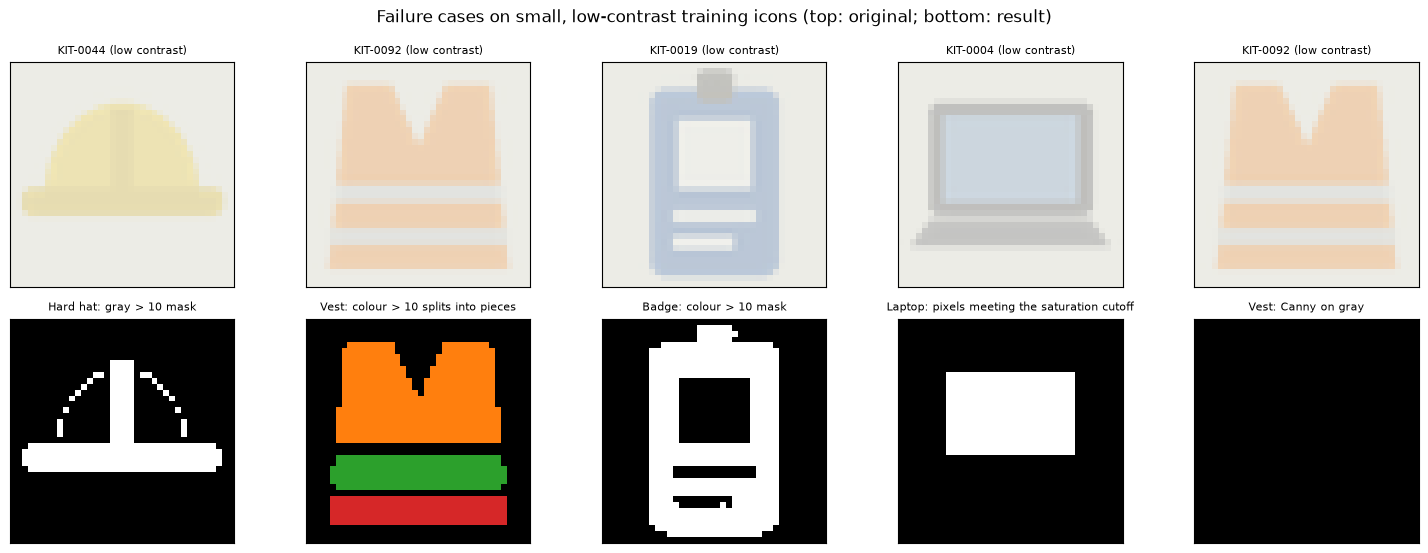

,failure_case,part,evidence,implication
0,Grayscale mask loses the low-contrast hard hat,B,median retention 44% at gray > 10; 38 of 38 ma...,Grayscale thresholds treat icons unequally
1,Low-contrast masks split into pieces,C,"55 icons: {('laptop', 'low'): 12, ('safety_ves...",Measuring only the largest piece changes the v...
2,Low-contrast badge loses foreground pixels,B,median retention 71% at colour > 10,Thresholding can change fill ratio and solidity
3,Blue-icon hue values overlap,D,"hue 103-113 for badge, laptop, and phone",Hue alone cannot separate these icons
4,Few low-contrast laptop pixels meet the satura...,D,median 45% of retained foreground pixels,Device hue shifts as contrast falls
5,Grayscale Canny finds no edges,E,"81 icons: {('hard_hat', 'low'): 38, ('safety_v...",One fixed edge setting does not suit every icon


In [8]:
# Failure cases, with evidence taken from the results above (training icons only)
def low_retention(representation, threshold, icon):
    """Median retention for one low-contrast icon type at one threshold (from Part B)."""
    match = mask_threshold_sweep[(mask_threshold_sweep["representation"] == representation)
                                 & (mask_threshold_sweep["threshold"] == threshold)
                                 & (mask_threshold_sweep["icon"] == icon)
                                 & (mask_threshold_sweep["contrast_level"] == "low")]
    return match["median_retention"].item()

low_hats_gray_20 = sweep[(sweep["representation"] == "gray") & (sweep["threshold"] == 20)
                         & (sweep["icon"] == "hard_hat") & (sweep["contrast_level"] == "low")]
blue_hues = feature_table.loc[feature_table["icon"].isin(["access_badge", "laptop", "phone"]), "hue"]
low_laptop = feature_table[(feature_table["icon"] == "laptop") & (feature_table["contrast_level"] == "low")]
gray_no_edges = edge_results[(edge_results["representation"] == "gray") & ~edge_results["has_edges"]]

failure_cases = pd.DataFrame([
    ("Grayscale mask loses the low-contrast hard hat", "B",
     f"median retention {low_retention('gray', 10, 'hard_hat'):.0%} at gray > 10; "
     f"{int(low_hats_gray_20['empty'].sum())} of {len(low_hats_gray_20)} masks empty at gray > 20",
     "Grayscale thresholds treat icons unequally"),
    ("Low-contrast masks split into pieces", "C",
     f"{len(split)} icons: {split.groupby(['icon', 'contrast_level']).size().to_dict()}",
     "Measuring only the largest piece changes the vest's aspect ratio"),
    ("Low-contrast badge loses foreground pixels", "B",
     f"median retention {low_retention('colour', 10, 'access_badge'):.0%} at colour > 10",
     "Thresholding can change fill ratio and solidity"),
    ("Blue-icon hue values overlap", "D",
     f"hue {blue_hues.min():.0f}-{blue_hues.max():.0f} for badge, laptop, and phone",
     "Hue alone cannot separate these icons"),
    ("Few low-contrast laptop pixels meet the saturation cutoff", "D",
     f"median {low_laptop['pct_pixels_meeting_saturation_cutoff'].median():.0f}% of retained foreground pixels",
     "Device hue shifts as contrast falls"),
    ("Grayscale Canny finds no edges", "E",
     f"{len(gray_no_edges)} icons: {gray_no_edges.groupby(['icon', 'contrast_level']).size().to_dict()}",
     "One fixed edge setting does not suit every icon"),
], columns=["failure_case", "part", "evidence", "implication"])
failure_cases.to_csv(OUTPUT_DIR / "failure_cases.csv", index=False)

# One figure showing five of the failures on small, low-contrast training examples
laptop_idx = train_icons.query("icon == 'laptop' and contrast_level == 'low' and scale_level == 'small'").index[0]
hat_idx, vest_idx, badge_idx = examples

def hue_mask(idx):
    """Foreground pixels that meet the saturation cutoff for hue measurement."""
    hsv = cv2.cvtColor(crops[idx]["rgb"], cv2.COLOR_RGB2HSV)
    return (crops[idx]["colour_diff"] > WORKING_THRESHOLD) & (hsv[..., 1] >= MIN_SATURATION)

_, vest_labels = cv2.connectedComponents((crops[vest_idx]["colour_diff"] > WORKING_THRESHOLD).astype(np.uint8),
                                         connectivity=8)
vest_pieces = plt.cm.tab10(vest_labels % 10)[..., :3]   # one colour per piece
vest_pieces[vest_labels == 0] = 0                        # background stays black
panels = [
    (hat_idx, crops[hat_idx]["gray_diff"] > WORKING_THRESHOLD, "gray", "Hard hat: gray > 10 mask"),
    (vest_idx, vest_pieces, None, "Vest: colour > 10 splits into pieces"),
    (badge_idx, crops[badge_idx]["colour_diff"] > WORKING_THRESHOLD, "gray", "Badge: colour > 10 mask"),
    (laptop_idx, hue_mask(laptop_idx), "gray", "Laptop: pixels meeting the saturation cutoff"),
    (vest_idx, edge_maps[(vest_idx, "gray")], "gray", "Vest: Canny on gray"),
]
fig, axes = plt.subplots(2, len(panels), figsize=(3 * len(panels), 5.6), squeeze=False)
for c, (idx, image, cmap, title) in enumerate(panels):
    axes[0, c].imshow(crops[idx]["rgb"], interpolation="nearest")
    axes[0, c].set_title(f"{train_icons.at[idx, 'card_id']} (low contrast)", fontsize=8)
    if cmap is None:
        axes[1, c].imshow(image, interpolation="nearest")
    else:
        axes[1, c].imshow(image, cmap=cmap, vmin=0, vmax=max(1, image.max()), interpolation="nearest")
    axes[1, c].set_title(title, fontsize=8)
for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle("Failure cases on small, low-contrast training icons (top: original; bottom: result)")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "failure_cases.png", dpi=120)
plt.show()

failure_cases